# PS-03: Sales Forecasting & Business Insights
Dataset: `supermarket_sales.csv` (9,994 orders, 2015-2018). Forecast target: **weekly total sales**.

**Dataset notes (found during inspection):** no Quantity/Price/Product columns, so `Sub Category` is the product proxy and
"quantity" = number of orders. `State` has one value. `Region` is not tied to `City`. Order values are almost uniformly distributed (looks synthetic).

## Step 1: Import libraries and load the dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, warnings
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

file_path = "supermarket_sales.csv"   # change if the file is elsewhere
df = pd.read_csv(file_path, encoding="utf-8-sig")   # utf-8-sig removes the hidden BOM
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
print("Shape:", df.shape)
df.head()

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1
Shape: (9994, 11)


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit,State
0,OD1,Harish,Oil & Masala,Masalas,Vellore,11-08-2017,North,1254,0.12,401.28,Tamil Nadu
1,OD2,Sudha,Beverages,Health Drinks,Krishnagiri,11-08-2017,South,749,0.18,149.80,Tamil Nadu
2,OD3,Hussain,Food Grains,Atta & Flour,Perambalur,06-12-2017,West,2360,0.21,165.20,Tamil Nadu
3,OD4,Jackson,Fruits & Veggies,Fresh Vegetables,Dharmapuri,10-11-2016,South,896,0.25,89.60,Tamil Nadu
4,OD5,Ridhesh,Food Grains,Organic Staples,Ooty,10-11-2016,South,2355,0.26,918.45,Tamil Nadu


## Step 2: Understand the dataset

In [2]:
df.info()
display(df.describe())
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum(), "| duplicate Order IDs:", df["Order ID"].duplicated().sum())
print(df.nunique())
for col in ["Category", "Region", "State"]:
    print(f"\n{col}:\n", df[col].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       9994 non-null   str    
 1   Customer Name  9994 non-null   str    
 2   Category       9994 non-null   str    
 3   Sub Category   9994 non-null   str    
 4   City           9994 non-null   str    
 5   Order Date     9994 non-null   str    
 6   Region         9994 non-null   str    
 7   Sales          9994 non-null   int64  
 8   Discount       9994 non-null   float64
 9   Profit         9994 non-null   float64
 10  State          9994 non-null   str    
dtypes: float64(2), int64(1), str(8)
memory usage: 859.0 KB


,Sales,Discount,Profit
count,9994.000000,9994.000000,9994.000000
mean,1496.596158,0.226817,374.937082
std,577.559036,0.074636,239.932881
min,500.000000,0.100000,25.250000
25%,1000.000000,0.160000,180.022500
50%,1498.000000,0.230000,320.780000
75%,1994.750000,0.290000,525.627500
max,2500.000000,0.350000,1120.950000


Missing values:
 Order ID         0
Customer Name    0
Category         0
Sub Category     0
City             0
Order Date       0
Region           0
Sales            0
Discount         0
Profit           0
State            0
dtype: int64
Duplicate rows: 0 | duplicate Order IDs: 0
Order ID         9994
Customer Name      50
Category            7
Sub Category       23
City               24
Order Date       1236
Region              5
Sales            1989
Discount           26
Profit           8380
State               1
dtype: int64

Category:
 Category
Snacks               1514
Eggs, Meat & Fish    1490
Fruits & Veggies     1418
Bakery               1413
Beverages            1400
Food Grains          1398
Oil & Masala         1361
Name: count, dtype: int64

Region:
 Region
West       3203
East       2848
Central    2323
South      1619
North         1
Name: count, dtype: int64

State:
 State
Tamil Nadu    9994
Name: count, dtype: int64


## Step 3: Data cleaning
`Order Date` mixes two display styles: `m/d/Y` (day always > 12) and `m-d-Y`. Testing showed the dash dates are also month-first
(their month-number distribution matches the slash dates' months, e.g. high in Sep/Nov/Dec). This is strong evidence, not proof.

In [3]:
df_clean = df.copy()
for col in ["Order ID", "Customer Name", "Category", "Sub Category", "City", "Region"]:
    df_clean[col] = df_clean[col].astype(str).str.strip()

dates = df_clean["Order Date"].astype(str).str.strip()
is_slash = dates.str.contains("/", regex=False)
parsed = pd.concat([pd.to_datetime(dates[is_slash], format="%m/%d/%Y"),
                    pd.to_datetime(dates[~is_slash], format="%m-%d-%Y")]).sort_index()
df_clean["Order Date"] = parsed

df_clean = df_clean.drop(columns=["State"]).drop_duplicates()
df_clean = df_clean.sort_values("Order Date").reset_index(drop=True)

print("Missing dates:", df_clean["Order Date"].isnull().sum())
print("Sales <= 0:", (df_clean["Sales"] <= 0).sum(), "| Discount outside 0-1:",
      ((df_clean["Discount"] < 0) | (df_clean["Discount"] > 1)).sum(), "| Profit <= 0:", (df_clean["Profit"] <= 0).sum())
print("Date range:", df_clean["Order Date"].min().date(), "to", df_clean["Order Date"].max().date())
print(df_clean["Order Date"].dt.year.value_counts().sort_index())
print(df_clean["Region"].value_counts())
df_clean.head()

Missing dates: 0
Sales <= 0: 0 | Discount outside 0-1: 0 | Profit <= 0: 0
Date range: 2015-01-03 to 2018-12-30
Order Date
2015    1993
2016    2102
2017    2587
2018    3312
Name: count, dtype: int64
Region
West       3203
East       2848
Central    2323
South      1619
North         1
Name: count, dtype: int64


,Order ID,Customer Name,Category,Sub Category,City,Order Date,Region,Sales,Discount,Profit
0,OD3324,Jackson,Bakery,Breads & Buns,Salem,2015-01-03,Central,864,0.26,380.16
1,OD740,Haseena,Bakery,Cakes,Nagercoil,2015-01-04,Central,2033,0.15,325.28
2,OD741,Vinne,Beverages,Health Drinks,Trichy,2015-01-04,Central,698,0.32,223.36
3,OD742,Sudha,Snacks,Chocolates,Dharmapuri,2015-01-04,Central,759,0.27,174.57
4,OD3873,Verma,"Eggs, Meat & Fish",Fish,Tirunelveli,2015-01-05,East,878,0.35,149.26


## Step 4: Exploratory data analysis

Total sales 14,956,982 | profit 3,747,121.20 | orders 9,994 | avg order 1,496.60
NOTE: no Quantity column, so 'quantity sold' = number of orders.

=== BY CATEGORY ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Category,,,,,
"Eggs, Meat & Fish",2267401,1490,1521.7,567357.2,15.2
Snacks,2237546,1514,1477.9,568178.8,15.0
Food Grains,2115272,1398,1513.1,529162.6,14.1
Bakery,2112281,1413,1494.9,528521.1,14.1
Fruits & Veggies,2100727,1418,1481.5,530400.4,14.0
Beverages,2085313,1400,1489.5,525605.8,13.9
Oil & Masala,2038442,1361,1497.8,497895.3,13.6



=== BY REGION ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Region,,,,,
West,4798743,3203,1498.2,1192004.6,32.1
East,4248368,2848,1491.7,1074345.6,28.4
Central,3468156,2323,1493.0,856806.8,23.2
South,2440461,1619,1507.4,623562.9,16.3
North,1254,1,1254.0,401.3,0.0



=== TOP 10 SUB CATEGORIES ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Sub Category,,,,,
Health Drinks,1051439,719,1462.4,267469.8,7.0
Soft Drinks,1033874,681,1518.2,258136.0,6.9
Cookies,768213,520,1477.3,190643.7,5.1
Breads & Buns,742586,502,1479.3,190765.0,5.0
Noodles,735435,495,1485.7,193685.8,4.9
Chocolates,733898,499,1470.7,183849.3,4.9
Masalas,697480,463,1506.4,168999.1,4.7
Cakes,685612,452,1516.8,168398.5,4.6
Biscuits,684083,459,1490.4,169357.6,4.6


=== BOTTOM 5 ===


,total_sales,orders,avg_order,total_profit,sales_share_%
Sub Category,,,,,
Dals & Pulses,523371,343,1525.9,130232.3,3.5
Chicken,520497,348,1495.7,124049.9,3.5
Organic Vegetables,520271,347,1499.3,133596.4,3.5
Organic Fruits,503402,348,1446.6,130862.3,3.4
Rice,498323,330,1510.1,126932.4,3.3


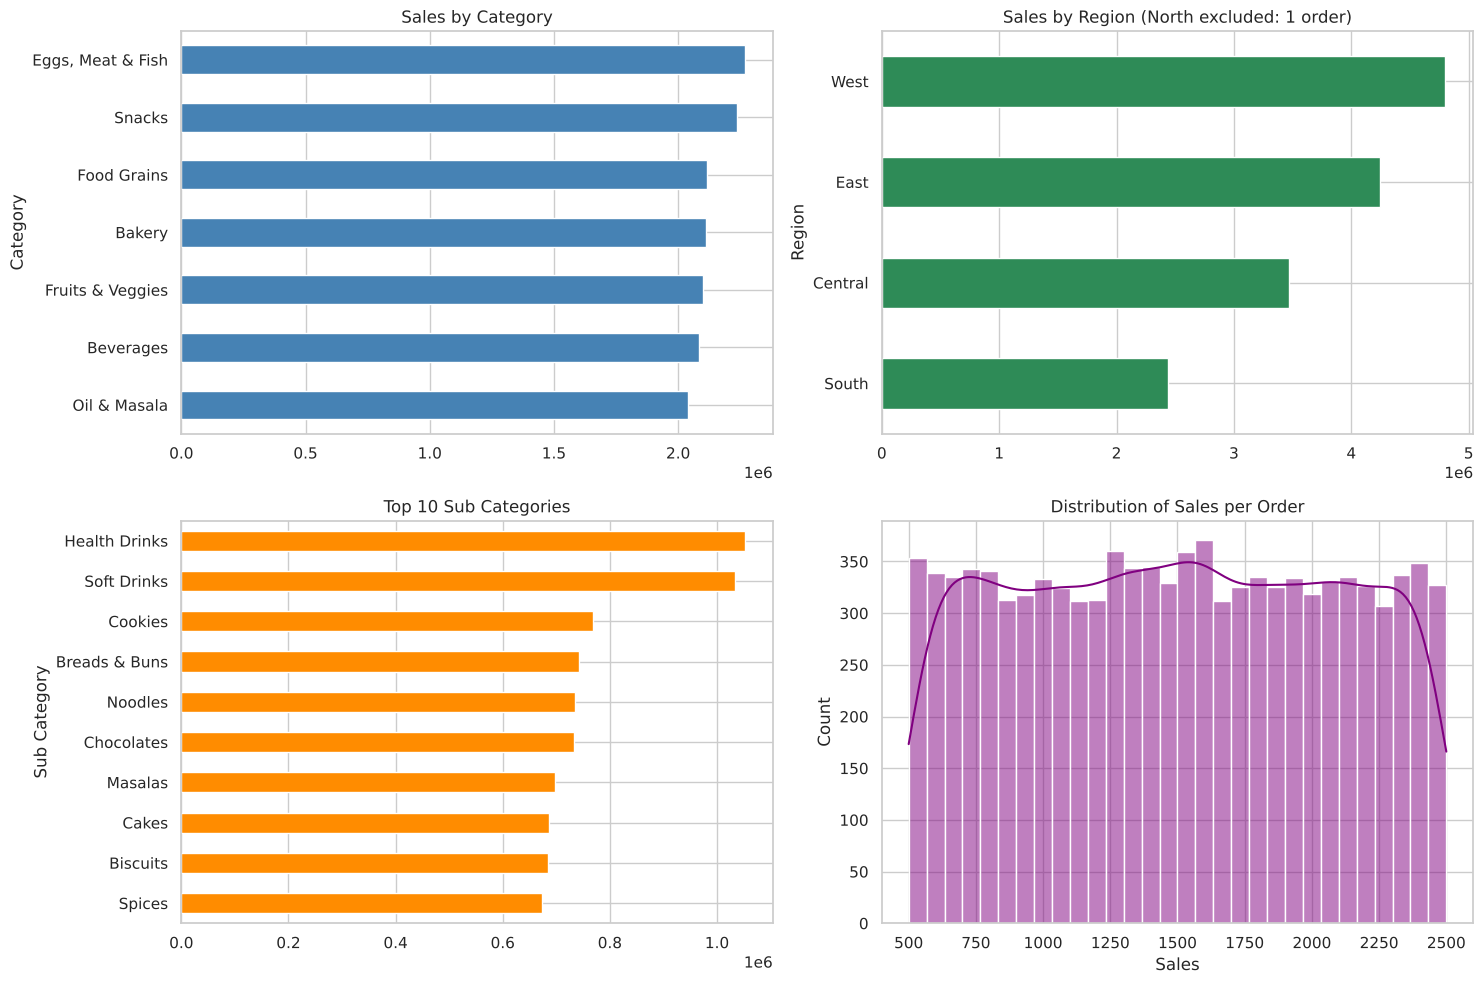

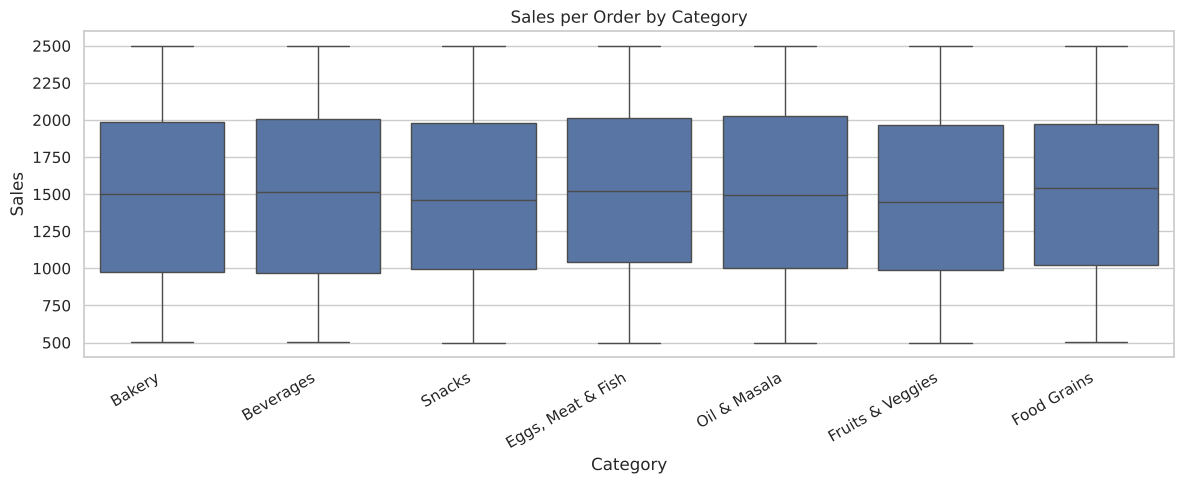

In [4]:
total_sales = df_clean["Sales"].sum()
print(f"Total sales {total_sales:,} | profit {df_clean['Profit'].sum():,.2f} | orders {len(df_clean):,} | avg order {df_clean['Sales'].mean():,.2f}")
print("NOTE: no Quantity column, so 'quantity sold' = number of orders.")

def summarize(by):
    out = (df_clean.groupby(by).agg(total_sales=("Sales", "sum"), orders=("Sales", "count"),
           avg_order=("Sales", "mean"), total_profit=("Profit", "sum"))
           .sort_values("total_sales", ascending=False))
    out["sales_share_%"] = (out["total_sales"] / total_sales * 100).round(1)
    return out.round(1)

for by in ["Category", "Region"]:
    print(f"\n=== BY {by.upper()} ==="); display(summarize(by))
sub_summary = summarize("Sub Category")
print("\n=== TOP 10 SUB CATEGORIES ==="); display(sub_summary.head(10))
print("=== BOTTOM 5 ==="); display(sub_summary.tail(5))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
df_clean.groupby("Category")["Sales"].sum().sort_values().plot(kind="barh", ax=axes[0,0], color="steelblue", title="Sales by Category")
df_clean[df_clean["Region"] != "North"].groupby("Region")["Sales"].sum().sort_values().plot(kind="barh", ax=axes[0,1], color="seagreen", title="Sales by Region (North excluded: 1 order)")
df_clean.groupby("Sub Category")["Sales"].sum().sort_values().tail(10).plot(kind="barh", ax=axes[1,0], color="darkorange", title="Top 10 Sub Categories")
sns.histplot(df_clean["Sales"], bins=30, kde=True, ax=axes[1,1], color="purple"); axes[1,1].set_title("Distribution of Sales per Order")
plt.tight_layout(); plt.show()

plt.figure(figsize=(12, 5)); sns.boxplot(data=df_clean, x="Category", y="Sales")
plt.xticks(rotation=30, ha="right"); plt.title("Sales per Order by Category"); plt.tight_layout(); plt.show()

## Step 5: Time-series analysis

Calendar days: 1458 | days with no orders: 222


,sales,orders,avg_order,sales_growth_%,orders_growth_%
Order Date,,,,,
2015,2975599,1993,1493.0,NaN,NaN
2016,3131959,2102,1490.0,5.3,5.5
2017,3871912,2587,1496.7,23.6,23.1
2018,4977512,3312,1502.9,28.6,28.0


,quarterly_sales
Order Date,
2015-01-01,435683
2015-04-01,573585
2015-07-01,833347
2015-10-01,1132984
2016-01-01,391996
2016-04-01,665382
2016-07-01,874977
2016-10-01,1199604
2017-01-01,503665


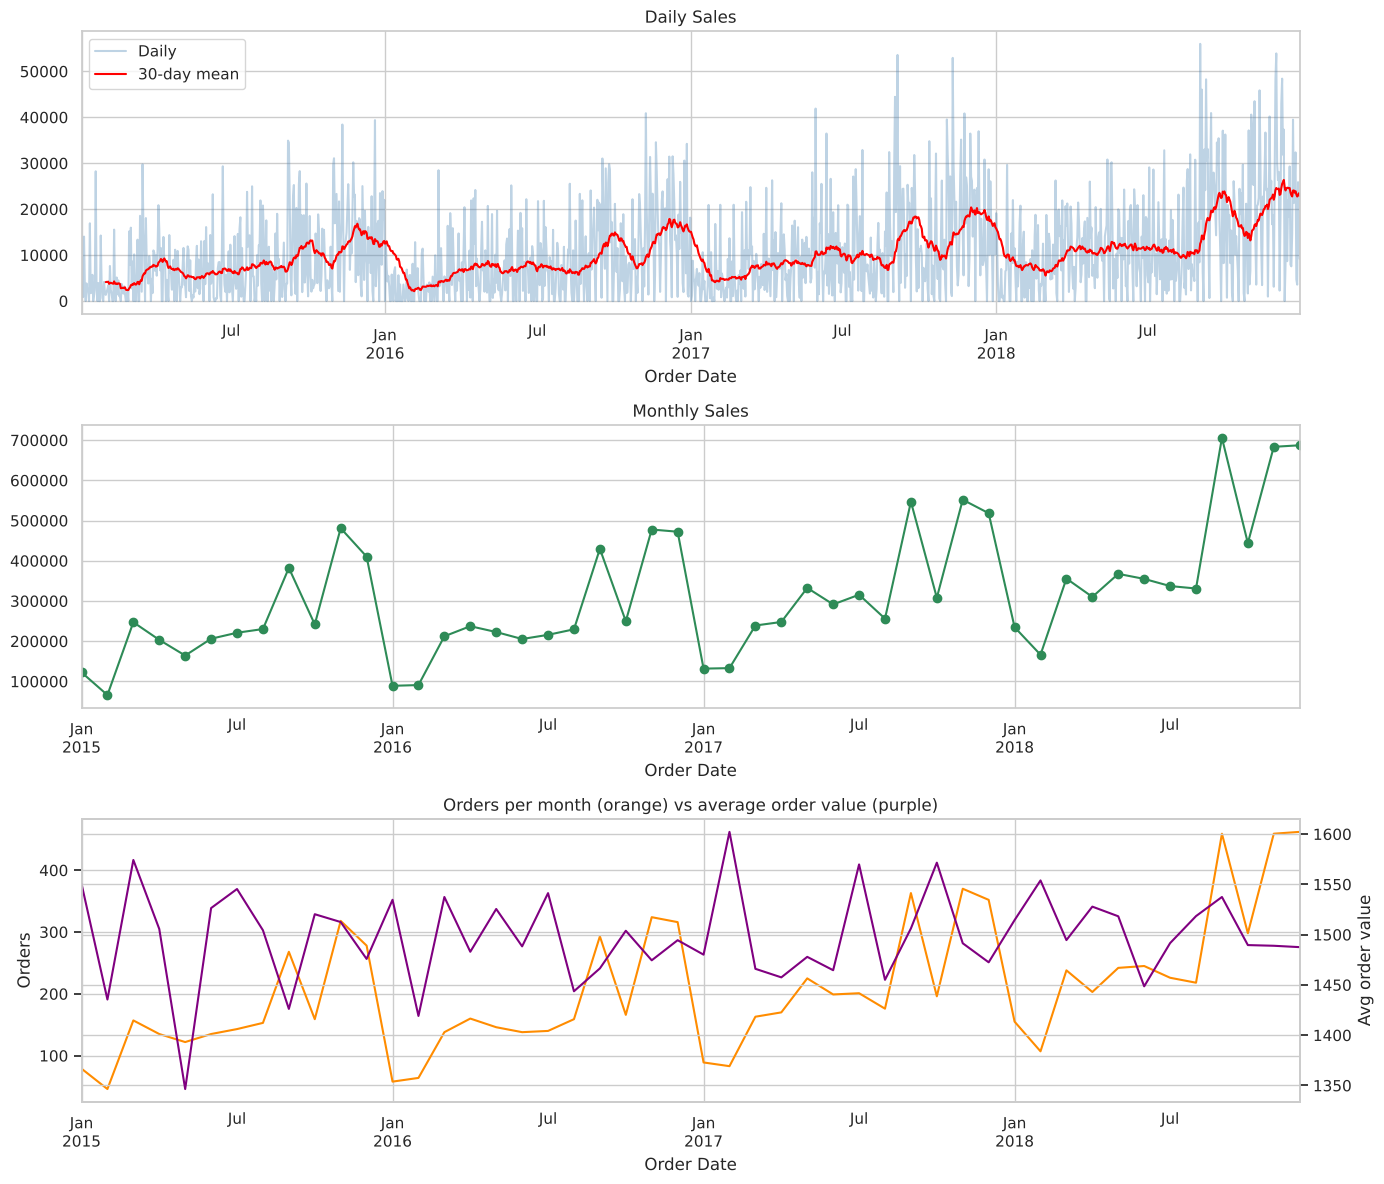

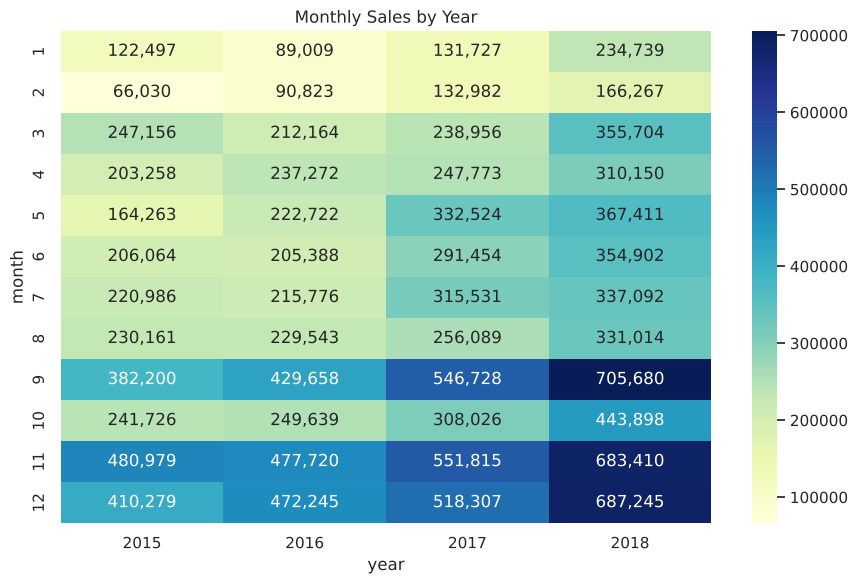

year,2015,2016,2017,2018,avg_share_%
month,,,,,
1,4.1,2.8,3.4,4.7,3.8
2,2.2,2.9,3.4,3.3,3.0
3,8.3,6.8,6.2,7.1,7.1
4,6.8,7.6,6.4,6.2,6.7
5,5.5,7.1,8.6,7.4,7.2
6,6.9,6.6,7.5,7.1,7.0
7,7.4,6.9,8.1,6.8,7.3
8,7.7,7.3,6.6,6.7,7.1
9,12.8,13.7,14.1,14.2,13.7


Unusual months (|z|>2): none


In [5]:
ts = df_clean.set_index("Order Date")
daily = ts["Sales"].resample("D").sum()
daily_orders = ts["Sales"].resample("D").count()
print("Calendar days:", len(daily), "| days with no orders:", (daily_orders == 0).sum())

monthly = ts.resample("MS").agg(sales=("Sales", "sum"), orders=("Sales", "count"), avg_order=("Sales", "mean"))
yearly = df_clean.groupby(df_clean["Order Date"].dt.year).agg(sales=("Sales", "sum"), orders=("Sales", "count"), avg_order=("Sales", "mean")).round(1)
yearly["sales_growth_%"] = (yearly["sales"].pct_change() * 100).round(1)
yearly["orders_growth_%"] = (yearly["orders"].pct_change() * 100).round(1)
display(yearly)
display(ts["Sales"].resample("QS").sum().to_frame("quarterly_sales"))

fig, axes = plt.subplots(3, 1, figsize=(14, 12))
daily.plot(ax=axes[0], alpha=0.35, color="steelblue", label="Daily"); daily.rolling(30).mean().plot(ax=axes[0], color="red", label="30-day mean")
axes[0].set_title("Daily Sales"); axes[0].legend()
monthly["sales"].plot(ax=axes[1], marker="o", color="seagreen", title="Monthly Sales")
monthly["orders"].plot(ax=axes[2], color="darkorange"); axes[2].set_ylabel("Orders")
ax3 = axes[2].twinx(); monthly["avg_order"].plot(ax=ax3, color="purple"); ax3.set_ylabel("Avg order value")
axes[2].set_title("Orders per month (orange) vs average order value (purple)")
plt.tight_layout(); plt.show()

mc = monthly.copy(); mc["year"] = mc.index.year; mc["month"] = mc.index.month
pivot = mc.pivot(index="month", columns="year", values="sales")
plt.figure(figsize=(9, 6)); sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu"); plt.title("Monthly Sales by Year"); plt.tight_layout(); plt.show()
share = (pivot / pivot.sum() * 100).round(1); share["avg_share_%"] = share.mean(axis=1).round(1)
display(share)

roll_mean = monthly["sales"].rolling(12, center=True, min_periods=6).mean()
roll_std = monthly["sales"].rolling(12, center=True, min_periods=6).std()
z = (monthly["sales"] - roll_mean) / roll_std
flag = z.abs() > 2
print("Unusual months (|z|>2):", monthly.index[flag].strftime("%Y-%m").tolist() if flag.any() else "none")

## Step 6: Prepare data for machine learning
Daily data is too sparse (15% zero-order days) and monthly has only 48 rows, so the target is **weekly sales** (weeks end Sunday; the 2-day first week is dropped).
Features use only information available at prediction time: time index, seasonal sin/cos, lags 1/2/4/52, and the previous-4-week mean (shifted so the current week is excluded).
The split is chronological: the last 26 weeks are the test set.

In [6]:
weekly_sales = ts["Sales"].resample("W-SUN").sum().iloc[1:]
data = pd.DataFrame({"sales": weekly_sales}); data.index.name = "week_end"
data["t"] = np.arange(len(data))
doy = data.index.dayofyear
data["season_sin"] = np.sin(2 * np.pi * doy / 365.25)
data["season_cos"] = np.cos(2 * np.pi * doy / 365.25)
for k in [1, 2, 4, 52]:
    data[f"lag_{k}"] = data["sales"].shift(k)
data["roll_mean_4"] = data["sales"].shift(1).rolling(4).mean()

assert np.isclose(data["lag_1"].iloc[5], data["sales"].iloc[4])
assert np.isclose(data["roll_mean_4"].iloc[10], data["sales"].iloc[6:10].mean())
print("Leakage checks passed.")

model_df = data.dropna().copy()
test_weeks = 26
train, test = model_df.iloc[:-test_weeks], model_df.iloc[-test_weeks:]
target = "sales"
feature_cols = [c for c in model_df.columns if c != target]
X_train, y_train, X_test, y_test = train[feature_cols], train[target], test[feature_cols], test[target]
print("Rows before/after dropna:", len(data), "/", len(model_df))
print("Train", X_train.shape, train.index.min().date(), "to", train.index.max().date())
print("Test ", X_test.shape, test.index.min().date(), "to", test.index.max().date())
print("Train ends before test starts:", train.index.max() < test.index.min())

Leakage checks passed.
Rows before/after dropna: 208 / 156
Train (130, 8) 2016-01-10 to 2018-07-01
Test  (26, 8) 2018-07-08 to 2018-12-30
Train ends before test starts: True


## Step 7: Baseline forecasting models
Naive (last week), 4-week moving average, seasonal naive (same week last year), and seasonal naive x growth (last year's value times the ratio of the last 52 weeks to the 52 before, past data only).

In [7]:
def evaluate(y_true, y_pred, name):
    assert (y_true > 0).all(), "Zero actuals: MAPE invalid"   # MAPE limitation guard
    return {"model": name, "MAE": round(mean_absolute_error(y_true, y_pred)),
            "RMSE": round(root_mean_squared_error(y_true, y_pred)),
            "R2": round(r2_score(y_true, y_pred), 3),
            "MAPE_%": round(float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100), 1)}

sum_last_52 = data["sales"].rolling(52).sum().shift(1)
sum_prev_52 = data["sales"].rolling(52).sum().shift(53)
growth = (sum_last_52 / sum_prev_52).reindex(X_test.index)
assert growth.notna().all()
print(f"Growth factor range on test weeks: {growth.min():.3f} to {growth.max():.3f}")

baseline_preds = pd.DataFrame({
    "Naive (last week)": X_test["lag_1"],
    "Moving average (4 weeks)": X_test["roll_mean_4"],
    "Seasonal naive (lag_52)": X_test["lag_52"],
    "Seasonal naive x growth": X_test["lag_52"] * growth})
baseline_results = pd.DataFrame([evaluate(y_test, baseline_preds[c], c) for c in baseline_preds.columns]).set_index("model")
display(baseline_results)
print("Mean weekly sales in test set:", round(y_test.mean()))

Growth factor range on test weeks: 1.194 to 1.287


,MAE,RMSE,R2,MAPE_%
model,,,,
Naive (last week),22118,29373,0.526,19.7
Moving average (4 weeks),33838,39037,0.162,27.6
Seasonal naive (lag_52),32064,37901,0.210,26.3
Seasonal naive x growth,22039,28728,0.546,19.4


Mean weekly sales in test set: 122412


## Step 8: Linear Regression vs Random Forest
Random forests cannot predict above the largest training value, which matters for a growing series.

In [8]:
models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)}
model_preds, ml_results = {}, []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = pd.Series(m.predict(X_test), index=X_test.index)
    model_preds[name] = p
    ml_results.append(evaluate(y_test, p, name))
comparison = pd.concat([baseline_results, pd.DataFrame(ml_results).set_index("model")]).sort_values("MAE")
display(comparison)

for name, p in model_preds.items():
    print(f"{name:20s} average error (pred - actual): {(p - y_test).mean():,.0f}")
print("Training max:", y_train.max(), "| test max:", y_test.max(),
      "| RF max prediction:", round(model_preds["Random Forest"].max()),
      "| LR max prediction:", round(model_preds["Linear Regression"].max()))
print(pd.Series(models["Linear Regression"].coef_, index=feature_cols).round(3))
print(pd.Series(models["Random Forest"].feature_importances_, index=feature_cols).sort_values(ascending=False).round(3))

,MAE,RMSE,R2,MAPE_%
model,,,,
Linear Regression,20300,24172,0.679,18.5
Seasonal naive x growth,22039,28728,0.546,19.4
Naive (last week),22118,29373,0.526,19.7
Random Forest,28647,34051,0.363,23.1
Seasonal naive (lag_52),32064,37901,0.210,26.3
Moving average (4 weeks),33838,39037,0.162,27.6


Linear Regression    average error (pred - actual): -6,222
Random Forest        average error (pred - actual): -17,352
Training max: 157948 | test max: 196342 | RF max prediction: 130018 | LR max prediction: 161588
t               203.618
season_sin    -7187.701
season_cos      517.704
lag_1             0.250
lag_2             0.238
lag_4            -0.087
lag_52            0.477
roll_mean_4      -0.247
dtype: float64
lag_52         0.439
lag_1          0.162
t              0.121
lag_2          0.082
season_cos     0.070
season_sin     0.064
lag_4          0.031
roll_mean_4    0.030
dtype: float64


## Step 9: Model evaluation
Walk-forward validation re-trains at four cut-offs. The first window (52 training weeks) is unreliable for Linear Regression; later windows are more meaningful.

Error by month (positive % = under-predicted):


,weeks,mean_actual,MAE,mean_pct_error
week_end,,,,
7,4,77277.2,16567.6,-20.0
8,4,70435.8,25859.6,-27.1
9,5,155463.6,17882.0,8.9
10,4,100371.5,16417.9,1.0
11,4,158909.8,17374.9,10.9
12,5,155485.6,26699.6,13.9


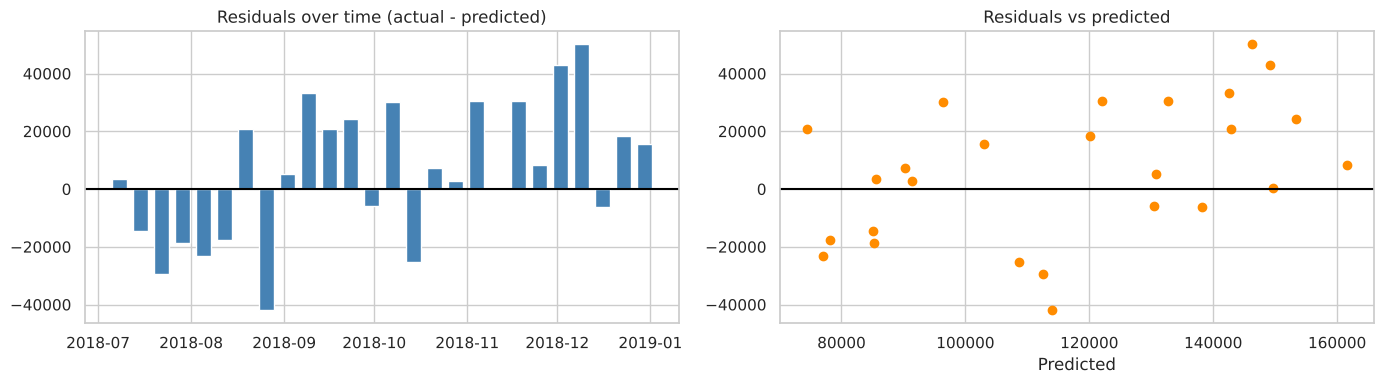

,test_window,train_weeks,LinReg_MAE,Baseline_MAE,Naive_MAE,LinReg_avg_error,LinReg_beats_baseline
0,2017-01-08 to 2017-07-02,52,50952,15919,20725,50952,False
1,2017-07-09 to 2017-12-31,78,20714,23212,26347,298,True
2,2018-01-07 to 2018-07-01,104,17357,19740,24116,10024,True
3,2018-07-08 to 2018-12-30,130,20300,22039,22118,-6222,True


Smallest weekly sales (MAPE safety): 8968


In [9]:
lr_pred = model_preds["Linear Regression"]
resid = y_test - lr_pred
by_month = pd.DataFrame({"actual": y_test, "abs_error": resid.abs(), "pct_error": resid / y_test * 100}
    ).groupby(y_test.index.month).agg(weeks=("actual", "count"), mean_actual=("actual", "mean"),
    MAE=("abs_error", "mean"), mean_pct_error=("pct_error", "mean")).round(1)
print("Error by month (positive % = under-predicted):"); display(by_month)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(resid.index, resid, width=5, color="steelblue"); axes[0].axhline(0, color="black"); axes[0].set_title("Residuals over time (actual - predicted)")
axes[1].scatter(lr_pred, resid, color="darkorange"); axes[1].axhline(0, color="black"); axes[1].set_title("Residuals vs predicted"); axes[1].set_xlabel("Predicted")
plt.tight_layout(); plt.show()

rows, n = [], len(model_df)
for end_train in [n - 104, n - 78, n - 52, n - 26]:
    tr, te = model_df.iloc[:end_train], model_df.iloc[end_train:end_train + 26]
    p = LinearRegression().fit(tr[feature_cols], tr["sales"]).predict(te[feature_cols])
    g = data["sales"].rolling(52).sum().shift(1).reindex(te.index) / data["sales"].rolling(52).sum().shift(53).reindex(te.index)
    base = te["lag_52"] * g
    rows.append({"test_window": f"{te.index.min().date()} to {te.index.max().date()}", "train_weeks": len(tr),
                 "LinReg_MAE": round(mean_absolute_error(te["sales"], p)),
                 "Baseline_MAE": round(mean_absolute_error(te["sales"], base)),
                 "Naive_MAE": round(mean_absolute_error(te["sales"], te["lag_1"])),
                 "LinReg_avg_error": round((p - te["sales"]).mean())})
wf = pd.DataFrame(rows); wf["LinReg_beats_baseline"] = wf["LinReg_MAE"] < wf["Baseline_MAE"]
display(wf)
print("Smallest weekly sales (MAPE safety):", model_df["sales"].min())

## Step 10: Actual vs predicted (final model: Linear Regression, 8 features)

,actual,predicted,baseline,error,pct_error
week_end,,,,,
2018-07-08,89091,85502.0,78842.0,-3589.0,-4.0
2018-07-15,70605,85008.0,70767.0,14403.0,20.4
2018-07-22,82953,112475.0,136017.0,29522.0,35.6
2018-07-29,66460,85216.0,70894.0,18756.0,28.2
2018-08-05,53816,77049.0,48925.0,23233.0,43.2
2018-08-12,60652,78160.0,57926.0,17508.0,28.9
2018-08-19,95191,74388.0,50871.0,-20803.0,-21.9
2018-08-26,72084,113979.0,124125.0,41895.0,58.1
2018-09-02,136031,130740.0,155229.0,-5291.0,-3.9


MAE 20,300 (16.6% of mean weekly sales) | bias -6,222 (-5.1%)
Weeks within +/-20%: 15 of 26


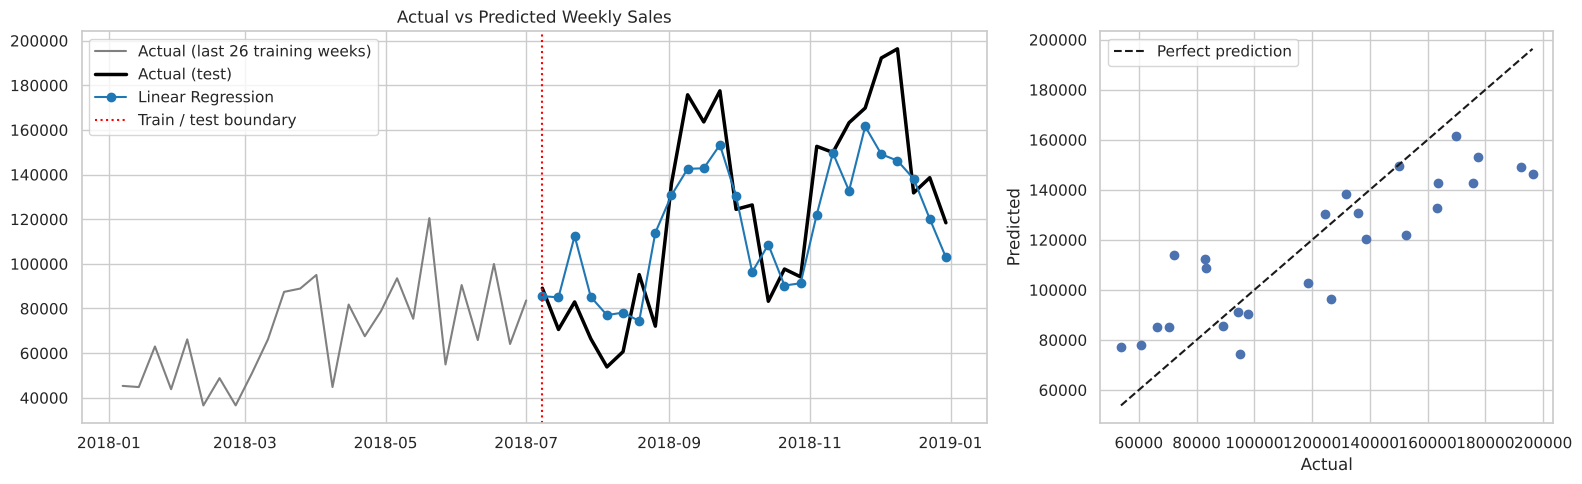

,weeks,actual,predicted,pct_error
week_end,,,,
7,4,309109,368201.0,19.1
8,4,281743,343576.0,21.9
9,5,777318,699853.0,-10.0
10,4,401486,386584.0,-3.7
11,4,635639,566138.0,-10.9
12,5,777428,656589.0,-15.5


In [10]:
baseline = X_test["lag_52"] * growth
comp = pd.DataFrame({"actual": y_test, "predicted": lr_pred.round(), "baseline": baseline.round()})
comp["error"] = comp["predicted"] - comp["actual"]
comp["pct_error"] = (comp["error"] / comp["actual"] * 100).round(1)
display(comp)
mae = mean_absolute_error(y_test, lr_pred); ms = y_test.mean()
print(f"MAE {mae:,.0f} ({mae/ms:.1%} of mean weekly sales) | bias {(lr_pred - y_test).mean():,.0f} ({(lr_pred - y_test).mean()/ms:.1%})")
print("Weeks within +/-20%:", (comp["pct_error"].abs() <= 20).sum(), "of", len(comp))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]; ctx = y_train.iloc[-26:]
ax.plot(ctx.index, ctx, color="gray", label="Actual (last 26 training weeks)")
ax.plot(y_test.index, y_test, color="black", linewidth=2.5, label="Actual (test)")
ax.plot(lr_pred.index, lr_pred, "o-", color="tab:blue", label="Linear Regression")
ax.axvline(y_test.index.min(), color="red", linestyle=":", label="Train / test boundary")
ax.set_title("Actual vs Predicted Weekly Sales"); ax.legend()
ax = axes[1]; lo, hi = min(y_test.min(), lr_pred.min()), max(y_test.max(), lr_pred.max())
ax.scatter(y_test, lr_pred); ax.plot([lo, hi], [lo, hi], "k--", label="Perfect prediction")
ax.set_xlabel("Actual"); ax.set_ylabel("Predicted"); ax.legend()
plt.tight_layout(); plt.show()

mcmp = comp.groupby(comp.index.month).agg(weeks=("actual", "count"), actual=("actual", "sum"), predicted=("predicted", "sum"))
mcmp["pct_error"] = ((mcmp["predicted"] - mcmp["actual"]) / mcmp["actual"] * 100).round(1)
display(mcmp)

## Step 11: Future forecast (next 4 weeks, recursive)
**How recursive forecasting works:** the model needs last week's sales, but for week 2 onward that value is not yet known, so the model's own prediction is fed back in as `lag_1`, `lag_2`, `lag_4`, and the rolling mean. Errors can therefore compound.

**Decision rule (set in advance):** if Linear Regression does not beat the seasonal-growth baseline at weeks 2-4 of the backtest, the baseline is presented as the main forecast.

Recursive function check passed.


,origins,LR_MAE,Baseline_MAE,Naive_MAE,LR_bias
h,,,,,
1,23,21198.0,24109.0,21022.0,-5834.0
2,23,22209.0,23563.0,31006.0,-6501.0
3,23,24870.0,23820.0,44131.0,-9085.0
4,23,24341.0,21563.0,50409.0,-11284.0


LR beats baseline at 1 of horizons 2-4  ->  main forecast: Seasonal naive x growth


,Baseline_forecast (main),LinReg_forecast,same_week_last_year_actual,Baseline_vs_last_year_%,LinReg_vs_last_year_%
2019-01-06,58262.0,88096.0,45321,28.6,94.4
2019-01-13,57589.0,83569.0,44797,28.6,86.6
2019-01-20,80979.0,84898.0,62992,28.6,34.8
2019-01-27,56331.0,79577.0,43819,28.6,81.6


4-week totals | Baseline 253,161 | LinReg 336,140 | same weeks last year 196,929


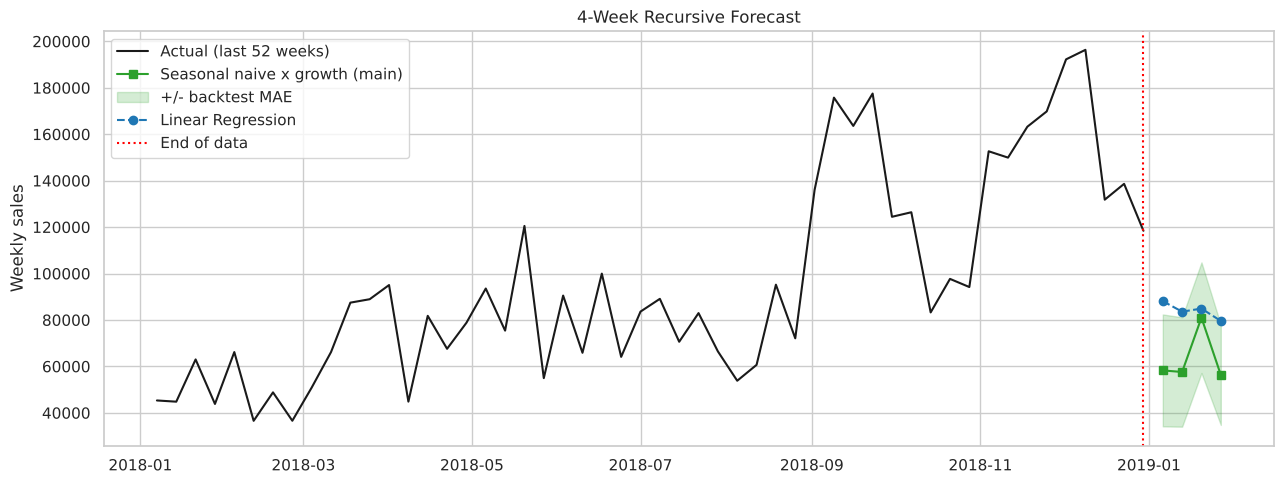

In [11]:
def recursive_forecast(model, history, horizon=4):
    hist = history.copy(); origin = hist.index[-1]; t_origin = data.loc[origin, "t"]
    preds, dates = [], []
    for h in range(1, horizon + 1):
        date = origin + pd.Timedelta(weeks=h); doy = date.dayofyear
        row = pd.DataFrame([[t_origin + h, np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25),
                             hist.iloc[-1], hist.iloc[-2], hist.iloc[-4], hist.iloc[-52], hist.iloc[-4:].mean()]],
                           columns=feature_cols)
        pred = float(model.predict(row)[0]); preds.append(pred); dates.append(date)
        hist = pd.concat([hist, pd.Series([pred], index=[date])])
    return pd.Series(preds, index=dates)

def seasonal_growth_forecast(history, horizon=4):
    g = history.iloc[-52:].sum() / history.iloc[-104:-52].sum()
    idx = [history.index[-1] + pd.Timedelta(weeks=h) for h in range(1, horizon + 1)]
    return pd.Series([history.iloc[-(53 - h)] * g for h in range(1, horizon + 1)], index=idx)

lr_130 = models["Linear Regression"]
chk = recursive_forecast(lr_130, data["sales"].loc[:train.index.max()], 1)
assert np.isclose(chk.iloc[0], model_preds["Linear Regression"].iloc[0]); print("Recursive function check passed.")

origins = model_df.index[len(train) - 1: len(model_df) - 4]
rows = []
for origin in origins:
    hist = data["sales"].loc[:origin]
    fc, bl = recursive_forecast(lr_130, hist, 4), seasonal_growth_forecast(hist, 4)
    actual = data["sales"].reindex(fc.index).values
    for h in range(4):
        rows.append({"h": h + 1, "actual": actual[h], "LR": fc.iloc[h], "Baseline": bl.iloc[h], "Naive": hist.iloc[-1]})
bt = pd.DataFrame(rows)
for m in ["LR", "Baseline", "Naive"]:
    bt[f"{m}_abs"] = (bt["actual"] - bt[m]).abs(); bt[f"{m}_err"] = bt[m] - bt["actual"]
summary = bt.groupby("h").agg(origins=("actual", "count"), LR_MAE=("LR_abs", "mean"), Baseline_MAE=("Baseline_abs", "mean"),
                              Naive_MAE=("Naive_abs", "mean"), LR_bias=("LR_err", "mean")).round()
display(summary)
lr_wins = int((summary.loc[2:4, "LR_MAE"] < summary.loc[2:4, "Baseline_MAE"]).sum())
primary = "Linear Regression" if lr_wins == 3 else "Seasonal naive x growth"
print(f"LR beats baseline at {lr_wins} of horizons 2-4  ->  main forecast: {primary}")

final_model = LinearRegression().fit(model_df[feature_cols], model_df["sales"])
hist_all = data["sales"]
fc_lr = recursive_forecast(final_model, hist_all, 4)
fc_base = seasonal_growth_forecast(hist_all, 4)
last_year = pd.Series([hist_all.iloc[-(53 - h)] for h in range(1, 5)], index=fc_lr.index)
future = pd.DataFrame({"Baseline_forecast (main)": fc_base.round(), "LinReg_forecast": fc_lr.round(),
                       "same_week_last_year_actual": last_year})
future["Baseline_vs_last_year_%"] = ((fc_base / last_year - 1) * 100).round(1)
future["LinReg_vs_last_year_%"] = ((fc_lr / last_year - 1) * 100).round(1)
display(future)
print(f"4-week totals | Baseline {fc_base.sum():,.0f} | LinReg {fc_lr.sum():,.0f} | same weeks last year {last_year.sum():,.0f}")

ctx = hist_all.iloc[-52:]; miss = summary["Baseline_MAE"].values
plt.figure(figsize=(13, 5))
plt.plot(ctx.index, ctx, "k", label="Actual (last 52 weeks)")
plt.plot(fc_base.index, fc_base, "s-", color="tab:green", label="Seasonal naive x growth (main)")
plt.fill_between(fc_base.index, fc_base - miss, fc_base + miss, color="tab:green", alpha=0.2, label="+/- backtest MAE")
plt.plot(fc_lr.index, fc_lr, "o--", color="tab:blue", label="Linear Regression")
plt.axvline(hist_all.index[-1], color="red", linestyle=":", label="End of data")
plt.title("4-Week Recursive Forecast"); plt.ylabel("Weekly sales"); plt.legend(); plt.tight_layout(); plt.show()

## Step 12: Category and regional performance
Region 'North' has 1 order and is excluded from comparisons. Order values are nearly identical across groups, so differences come from order counts.

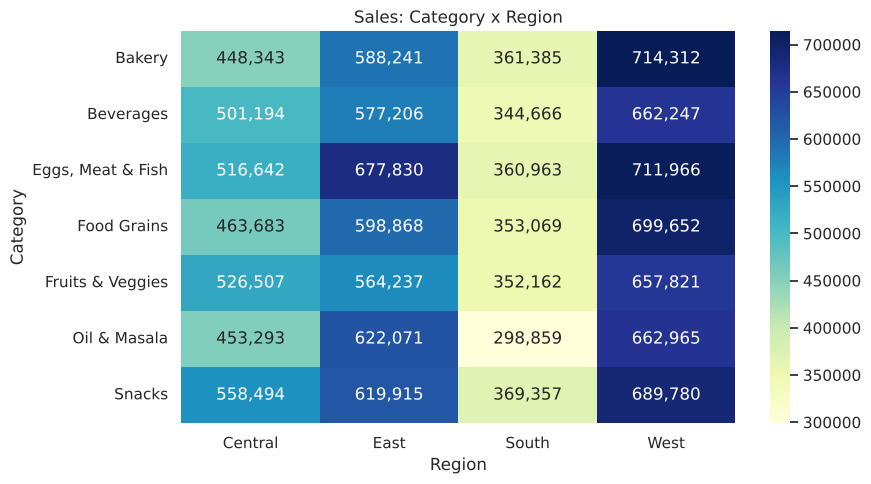

year,2015,2016,2017,2018,growth_2015_to_2018_%
Category,,,,,
Bakery,433979,487965,504263,686074,58.1
Beverages,409091,425719,543575,706928,72.8
"Eggs, Meat & Fish",482982,462055,565101,757263,56.8
Food Grains,356704,438736,609338,710494,99.2
Fruits & Veggies,409212,468441,516400,706674,72.7
Oil & Masala,423918,412725,562942,637603,50.4
Snacks,459713,436318,569039,772476,68.0


year,2015,2016,2017,2018,growth_2015_to_2018_%
Region,,,,,
Central,689710,701119,904462,1172865,70.1
East,773288,970983,1132477,1371620,77.4
South,525032,509161,626838,779430,48.5
West,987569,950696,1206881,1653597,67.4


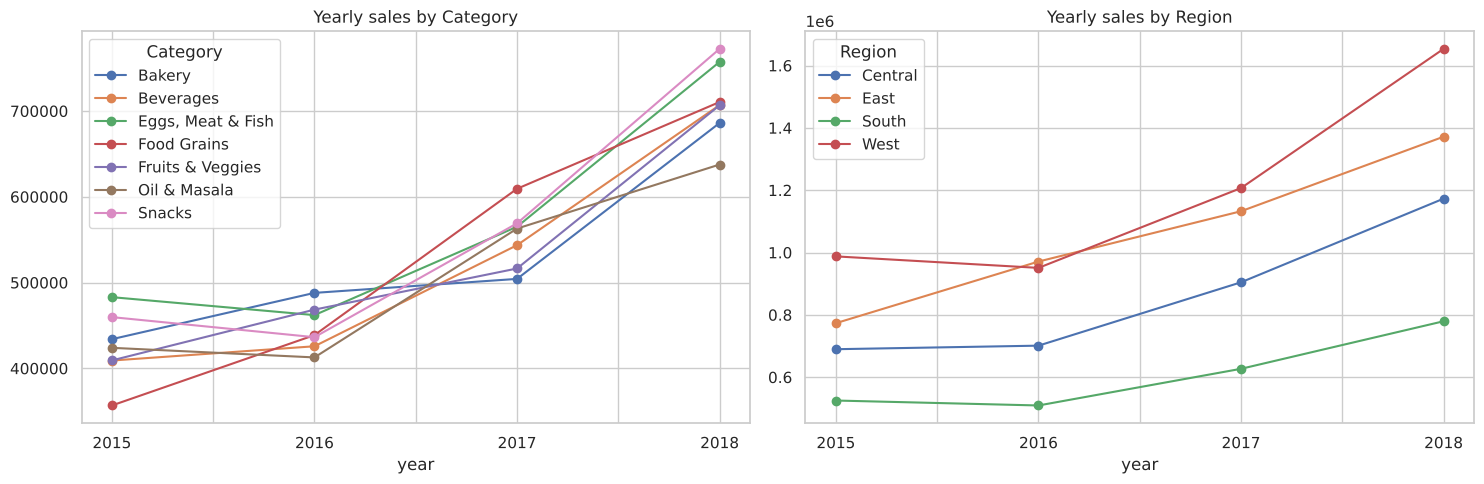

Share of each category's sales in Sep/Nov/Dec (%):


,peak_share_%
Category,
Fruits & Veggies,43.6
Snacks,43.1
Bakery,42.9
"Eggs, Meat & Fish",42.9
Food Grains,42.1
Beverages,41.6
Oil & Masala,40.6


,total_sales,orders,avg_order,total_profit,sales_share_%
Sub Category,,,,,
Health Drinks,1051439,719,1462.4,267469.8,7.0
Soft Drinks,1033874,681,1518.2,258136.0,6.9


In [12]:
d = df_clean[df_clean["Region"] != "North"].copy()
d["year"] = d["Order Date"].dt.year

# Category x Region (sales)
cr = d.pivot_table(index="Category", columns="Region", values="Sales", aggfunc="sum")
plt.figure(figsize=(9, 5)); sns.heatmap(cr, annot=True, fmt=",.0f", cmap="YlGnBu"); plt.title("Sales: Category x Region"); plt.tight_layout(); plt.show()

# Category and Region by year
cy = d.pivot_table(index="Category", columns="year", values="Sales", aggfunc="sum")
cy["growth_2015_to_2018_%"] = ((cy[2018] / cy[2015] - 1) * 100).round(1)
display(cy)
ry = d.pivot_table(index="Region", columns="year", values="Sales", aggfunc="sum")
ry["growth_2015_to_2018_%"] = ((ry[2018] / ry[2015] - 1) * 100).round(1)
display(ry)

# Yearly trend lines
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cy.drop(columns="growth_2015_to_2018_%").T.plot(ax=axes[0], marker="o", title="Yearly sales by Category")
ry.drop(columns="growth_2015_to_2018_%").T.plot(ax=axes[1], marker="o", title="Yearly sales by Region")
plt.tight_layout(); plt.show()

# Seasonality by category: share of sales in Sep+Nov+Dec
d["month"] = d["Order Date"].dt.month
peak_share = (d[d["month"].isin([9, 11, 12])].groupby("Category")["Sales"].sum() / d.groupby("Category")["Sales"].sum() * 100).round(1)
print("Share of each category's sales in Sep/Nov/Dec (%):"); display(peak_share.sort_values(ascending=False).to_frame("peak_share_%"))

# Sub-category inside Beverages (Health/Soft Drinks lead the sub-category ranking)
display(summarize("Sub Category").loc[lambda x: x.index.isin(
    df_clean.loc[df_clean["Category"] == "Beverages", "Sub Category"].unique())])

## Step 13: Business insights (computed from the results above)

In [13]:
cat = df_clean.groupby("Category")["Sales"].sum().sort_values(ascending=False)
reg = d.groupby("Region")["Sales"].sum().sort_values(ascending=False)
reg_orders = d.groupby("Region")["Sales"].count()
sub = df_clean.groupby("Sub Category")["Sales"].sum().sort_values(ascending=False)
mshare = (pivot / pivot.sum() * 100).mean(axis=1)
qshare = df_clean.groupby(df_clean["Order Date"].dt.quarter)["Sales"].sum() / df_clean["Sales"].sum() * 100

print("1. CATEGORIES ARE CLOSE: leader", cat.index[0], f"({cat.iloc[0]/cat.sum():.1%}) vs last", cat.index[-1],
      f"({cat.iloc[-1]/cat.sum():.1%}); gap {(cat.iloc[0]/cat.iloc[-1]-1):.0%}. No category dominates.")
print(f"2. REGIONS DIFFER: {reg.index[0]} {reg.iloc[0]/reg.sum():.1%} vs {reg.index[-1]} {reg.iloc[-1]/reg.sum():.1%}. "
      f"Driven by order counts ({reg_orders[reg.index[0]]:,} vs {reg_orders[reg.index[-1]]:,}); avg order value is similar everywhere.")
print(f"3. TOP SUB-CATEGORIES: {sub.index[0]} and {sub.index[1]} ({sub.iloc[0]/sub.sum():.1%} and {sub.iloc[1]/sub.sum():.1%}); "
      f"third place {sub.index[2]} is {sub.iloc[2]/sub.iloc[1]-1:.0%} lower.")
print(f"4. GROWTH IS FROM MORE ORDERS, not bigger orders: orders {yearly['orders'].iloc[0]:,} -> {yearly['orders'].iloc[-1]:,}; "
      f"avg order {yearly['avg_order'].iloc[0]:,.0f} -> {yearly['avg_order'].iloc[-1]:,.0f}.")
print(f"5. SEASONALITY (repeats in all 4 years): Sep+Nov+Dec average {mshare[[9,11,12]].sum():.1f}% of annual sales; "
      f"Jan+Feb only {mshare[[1,2]].sum():.1f}%. Q4 = {qshare[4]:.1f}% of all sales, Q1 = {qshare[1]:.1f}%.")
print("6. FORECASTING: weekly errors are ~17% of weekly sales, and the model under-predicts peaks / over-predicts quiet months. "
      "Use forecasts for rough planning and seasonal scale, not precise weekly orders.")
print("\nSuggested actions (judgement, based on the patterns above; cost and stock data are not in the dataset):")
print(" - Plan inventory and staffing around the Sep/Nov/Dec peaks and the Jan/Feb trough, using last year's same-week sales scaled by recent growth.")
print(" - Review why West and East generate more orders than South and Central (data cannot say why; Region is not tied to City in this file).")
print(" - Beverages ranks low as a category but holds the two top sub-categories: check the other Beverages sub-categories.")
print(" - Collect quantity, unit price, and product names to enable real product-level and price analysis.")

1. CATEGORIES ARE CLOSE: leader Eggs, Meat & Fish (15.2%) vs last Oil & Masala (13.6%); gap 11%. No category dominates.
2. REGIONS DIFFER: West 32.1% vs South 16.3%. Driven by order counts (3,203 vs 1,619); avg order value is similar everywhere.
3. TOP SUB-CATEGORIES: Health Drinks and Soft Drinks (7.0% and 6.9%); third place Cookies is -26% lower.
4. GROWTH IS FROM MORE ORDERS, not bigger orders: orders 1,993 -> 3,312; avg order 1,493 -> 1,503.
5. SEASONALITY (repeats in all 4 years): Sep+Nov+Dec average 42.6% of annual sales; Jan+Feb only 6.7%. Q4 = 36.9% of all sales, Q1 = 14.0%.
6. FORECASTING: weekly errors are ~17% of weekly sales, and the model under-predicts peaks / over-predicts quiet months. Use forecasts for rough planning and seasonal scale, not precise weekly orders.

Suggested actions (judgement, based on the patterns above; cost and stock data are not in the dataset):
 - Plan inventory and staffing around the Sep/Nov/Dec peaks and the Jan/Feb trough, using last year's sa

## Step 14: Summary, conclusion and limitations

**What was done:** cleaned the data (fixed mixed date formats, dropped constant `State`), analysed categories, regions and time trends, built weekly features without leakage, compared 4 baselines with Linear Regression and Random Forest on a chronological 26-week test, and produced a 4-week recursive forecast.

**Model results (26-week test, one-step-ahead):**

| Model | MAE | RMSE | R² | MAPE |
|---|---|---|---|---|
| Linear Regression | 20,300 | 24,172 | 0.679 | 18.5% |
| Seasonal naive x growth | 22,039 | 28,728 | 0.546 | 19.4% |
| Naive (last week) | 22,118 | 29,373 | 0.526 | 19.7% |
| Random Forest | 28,647 | 34,051 | 0.363 | 23.1% |

- Linear Regression beat the best baseline in 3 of 4 walk-forward windows, by 8-12%, but the margin is modest and it failed badly with only 52 training weeks.
- Random Forest cannot predict above values seen in training (max 130,018 vs actual up to 196,342), so it suits this growing series poorly.
- A log-target version was tested and was not better.
- In 4-week recursive backtests, Linear Regression beat the baseline only at weeks 1-2, not at weeks 3-4, so by the pre-set rule **the seasonal-growth baseline is the main forecast** and Linear Regression is shown for comparison.

**Conclusion:** the forecasts capture direction and rough seasonal scale (about 17% typical weekly error), not precise weekly numbers.

**Limitations:**
1. Only 4 years (48 months); each calendar month has 4 observations; the first year is consumed by the 52-week lag.
2. A single 26-week test window; results are noisy and the model's bias changed sign across windows.
3. Test scores are one-step-ahead and are optimistic for multi-week forecasts. The backtest is concentrated in high-sales months, so it says little about January accuracy.
4. The model over-predicted quiet months and under-predicted peaks; Linear Regression's January 2019 forecast (~336k for 4 weeks) is 71% above the same weeks of 2018 and likely too high.
5. Dash-format dates were interpreted as month-first based on strong but indirect evidence.
6. No quantity, price or product columns; `Region` is unrelated to `City`; order values look synthetic (uniform), and profit is positive on every order, so conclusions about profitability or real-world causes are not supported.
7. The dataset ends on 2018-12-30, so the forecast cannot be checked against actuals.